<font color=#FF0000>Section A: **Data Analysis & Preprocessing**</font>

In [ ]:
import pandas as pd

# loading the training dataset
df_train = pd.read_csv('train.csv')

df_train.head()

,ID,Sports,Interview Text,Speaker,Type,Labels
0,1,Tennis,"I don't know, I can't really think of anythin...",MATS WILANDER,Individual,7
1,2,Tennis,"No, and don't tell me what is going on. I don...",JIM COURIER,Individual,7
2,3,Golf,"Yeah, I think I'm always pretty good no matt...",PERNILLA LINDBERG,Individual,2
3,4,Baseball,"I was going to say, Marcus over here was in th...",HAROLD REYNOLDS,Team,4
4,5,Golf,Obviously today was more of a grind than last...,DAVID TOMS,Individual,2


In [ ]:
# identifying the number of examples per class and the total number of unique labels
label_counts = df_train['Labels'].value_counts().sort_index()
print("\nNumber of examples per class:\n", label_counts)
print("\nTotal number of unique labels:", len(label_counts))
df_train.describe()


Number of examples per class:
 Labels
1     53
2    133
3     19
4    101
5     82
6     31
7    130
8     22
Name: count, dtype: int64

Total number of unique labels: 8


,ID,Labels
count,571.000000,571.000000
mean,286.000000,4.311734
std,164.977776,2.176635
min,1.000000,1.000000
25%,143.500000,2.000000
50%,286.000000,4.000000
75%,428.500000,7.000000
max,571.000000,8.000000


In [ ]:
import pandas as pd
import re
import string

# Define your custom stopwords
basic_stopwords = set([
    "a", "an", "the", "and", "or", "but", "if", "while", "with", "of", "at", "by", "for", "to",
    "in", "on", "from", "up", "down", "out", "over", "under", "again", "further", "then", "once",
    "here", "there", "when", "where", "why", "how", "all", "any", "both", "each", "few", "more",
    "most", "other", "some", "such", "no", "nor", "not", "only", "own", "same", "so", "than", "too",
    "very", "can", "will", "just", "don", "should", "now", "is", "are", "was", "were", "be", "been", "being",
    "have", "has", "had", "do", "does", "did", "having", "i", "me", "my", "myself", "we", "our", "ours",
    "you", "your", "yours", "he", "him", "his", "she", "her", "they", "them", "their", "it's", "that", "this"
])

# Cleaning function
def basic_clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", '', text)
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [word for word in tokens if word not in basic_stopwords]
    return ' '.join(tokens)

# Apply cleaning and save to new column
df_train['Cleaned Interview Text'] = df_train['Interview Text'].astype(str).apply(basic_clean_text)

# View result
df_train[['Interview Text', 'Cleaned Interview Text']].head()


,Interview Text,Cleaned Interview Text
0,"I don't know, I can't really think of anythin...",dont know cant really think anything playing l...
1,"No, and don't tell me what is going on. I don...",dont tell what going dont dont tell what going...
2,"Yeah, I think I'm always pretty good no matt...",yeah think im always pretty good matter fans a...
3,"I was going to say, Marcus over here was in th...",going say marcus finals mvp american league si...
4,Obviously today was more of a grind than last...,obviously today grind last thursday still stil...


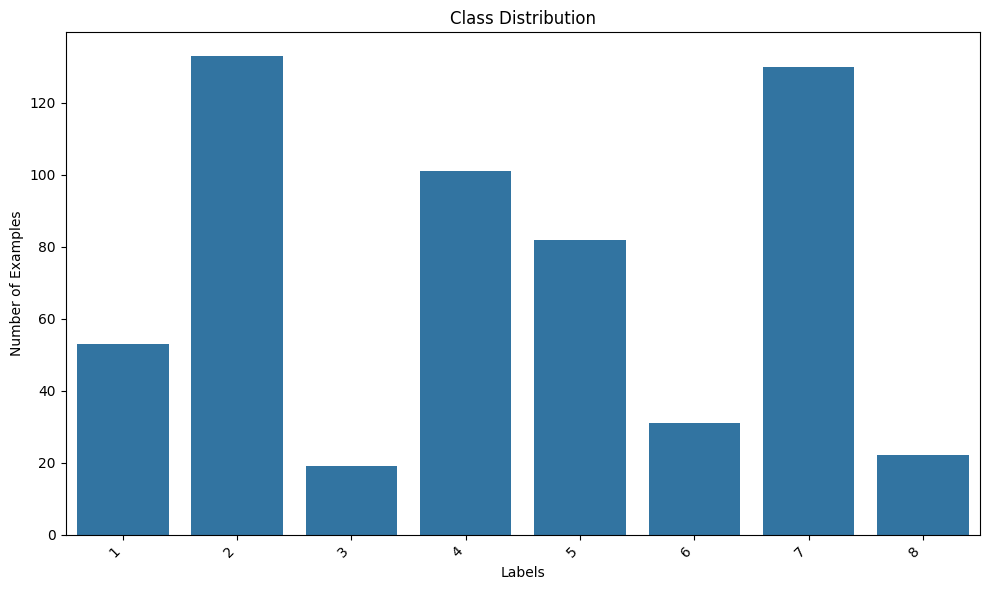

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# creating a bar plot to visualize the count of each label in the dataset
plt.figure(figsize=(10, 6))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title('Class Distribution')
plt.xlabel('Labels')
plt.ylabel('Number of Examples')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


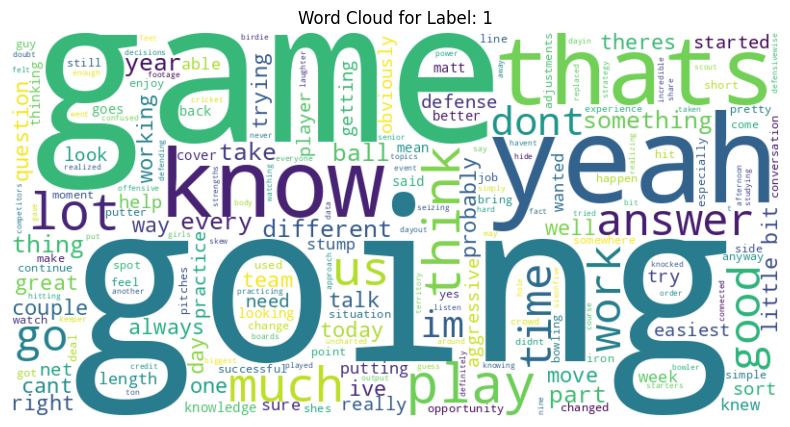

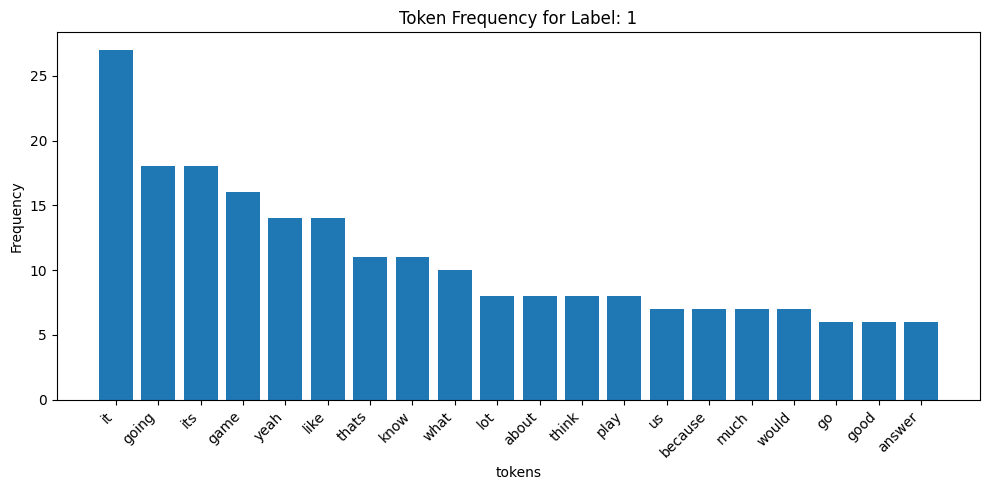

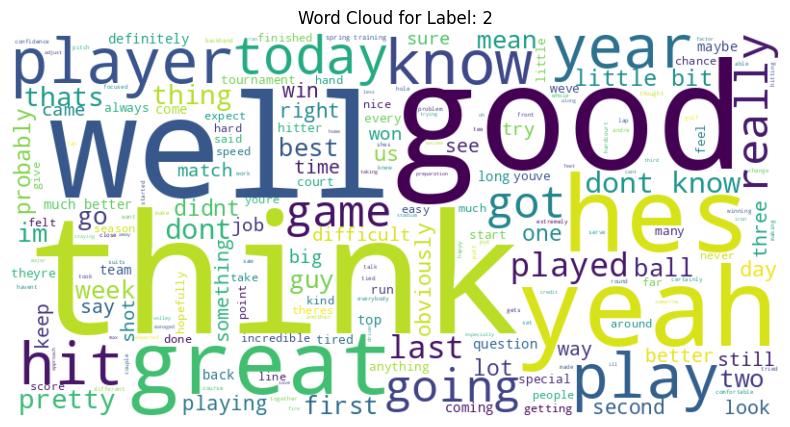

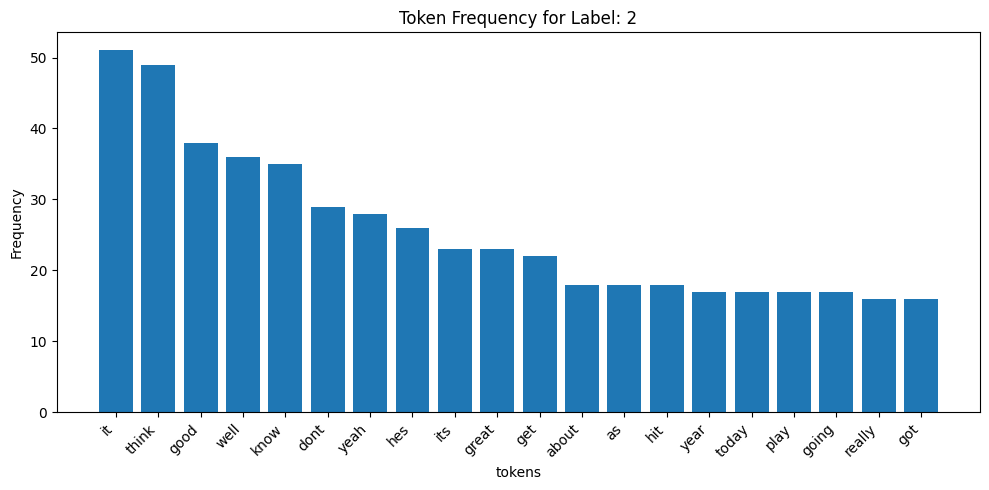

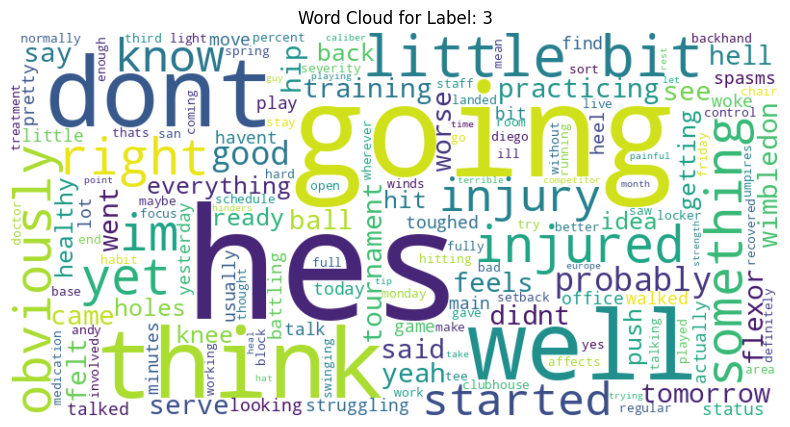

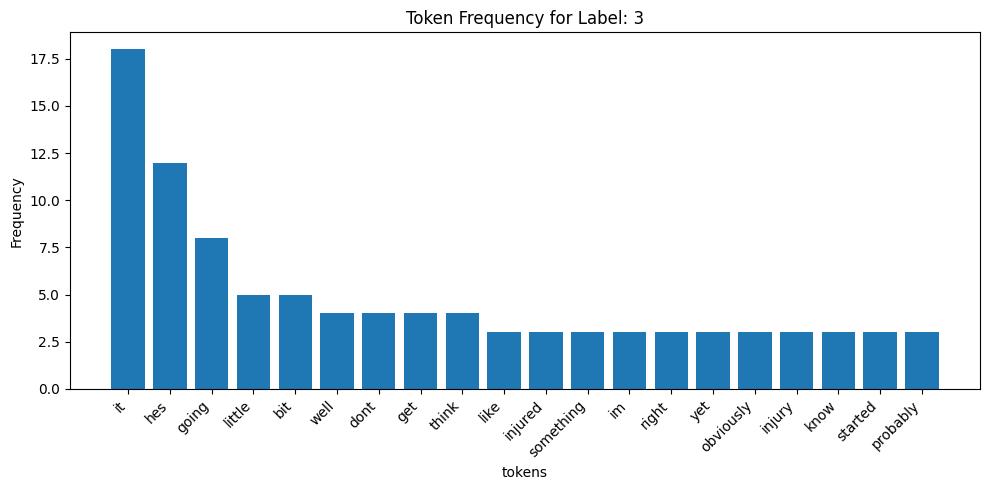

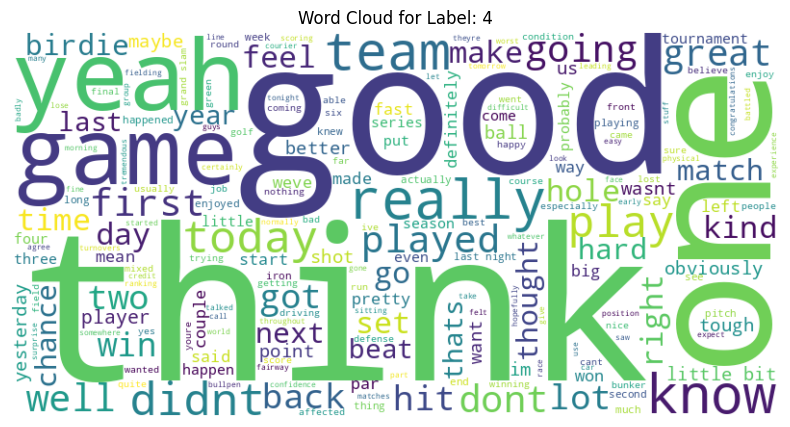

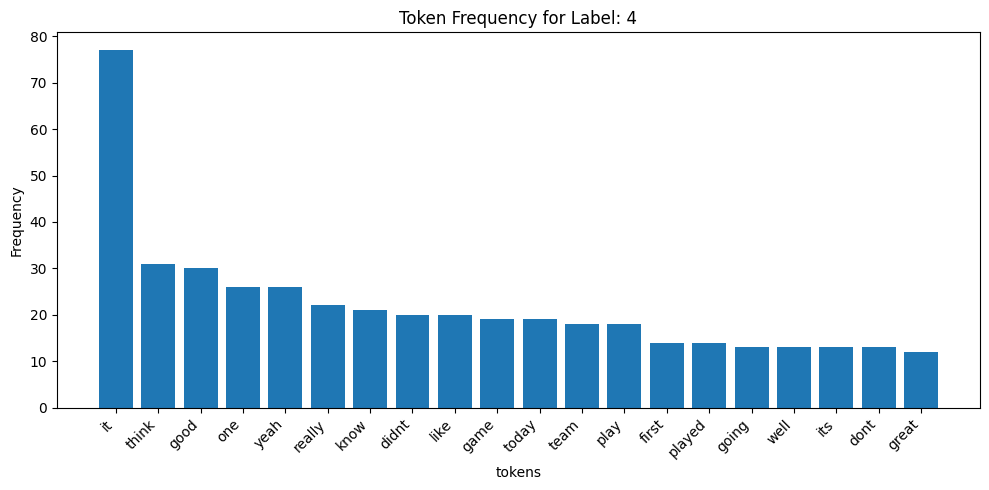

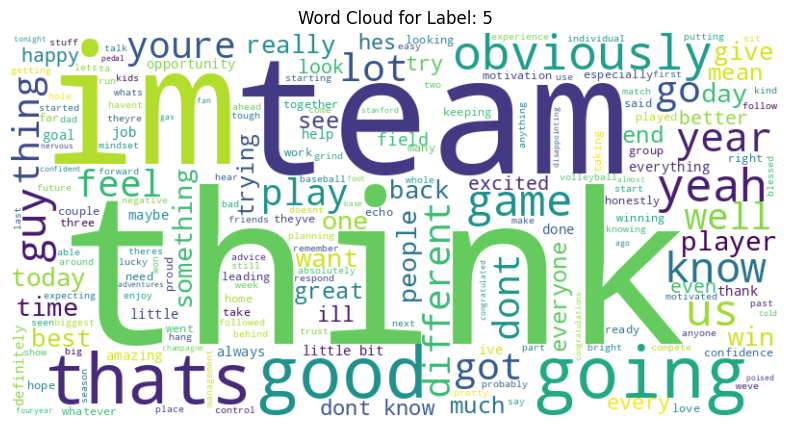

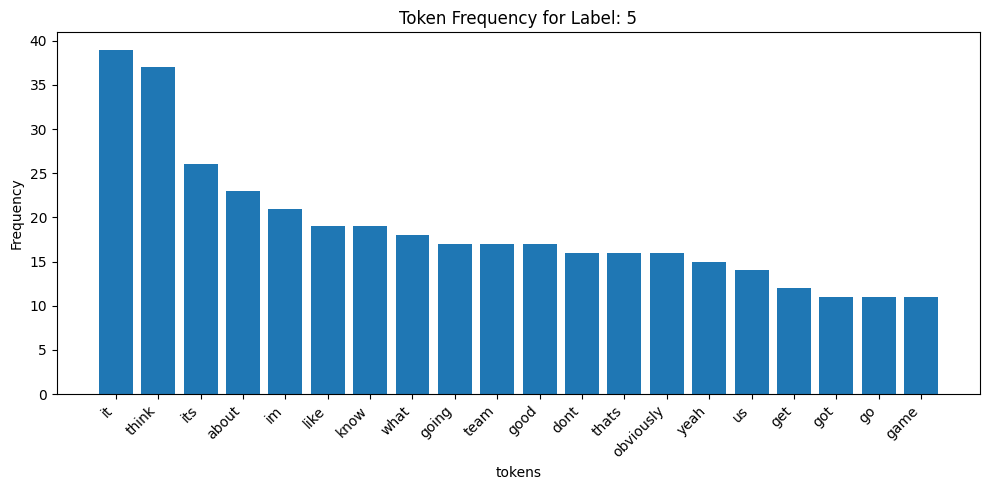

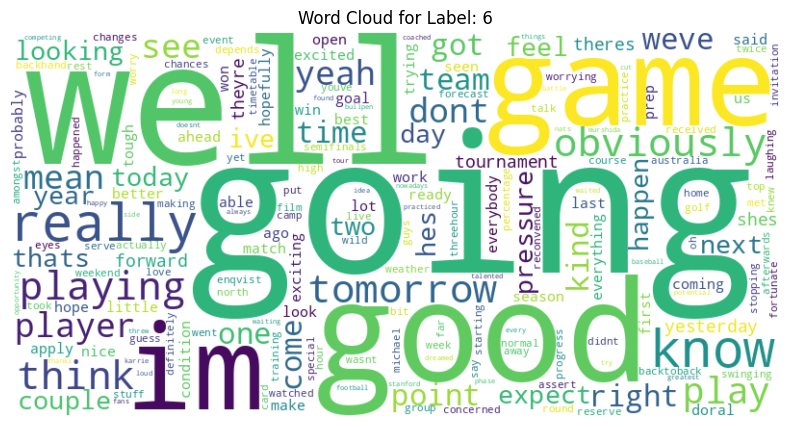

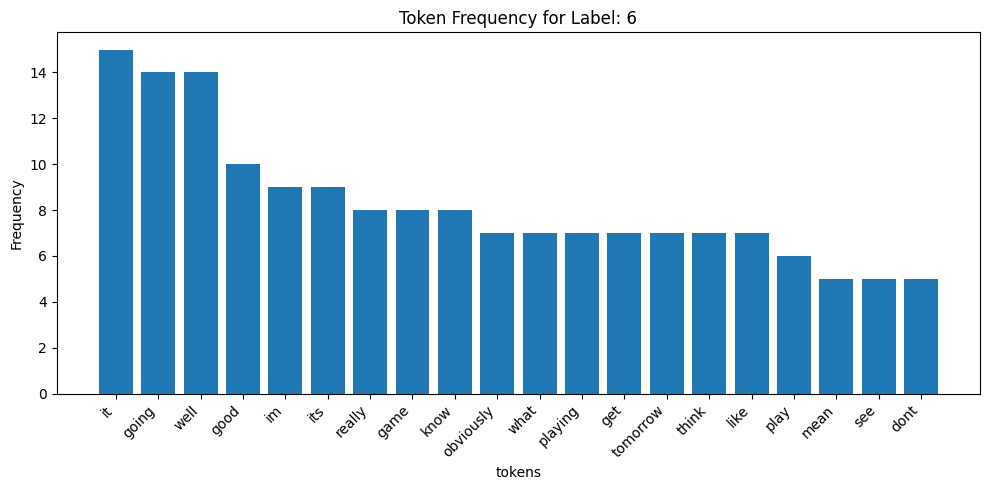

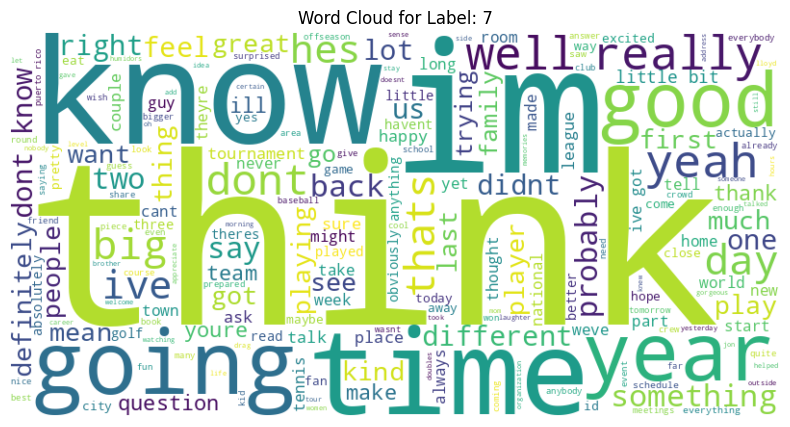

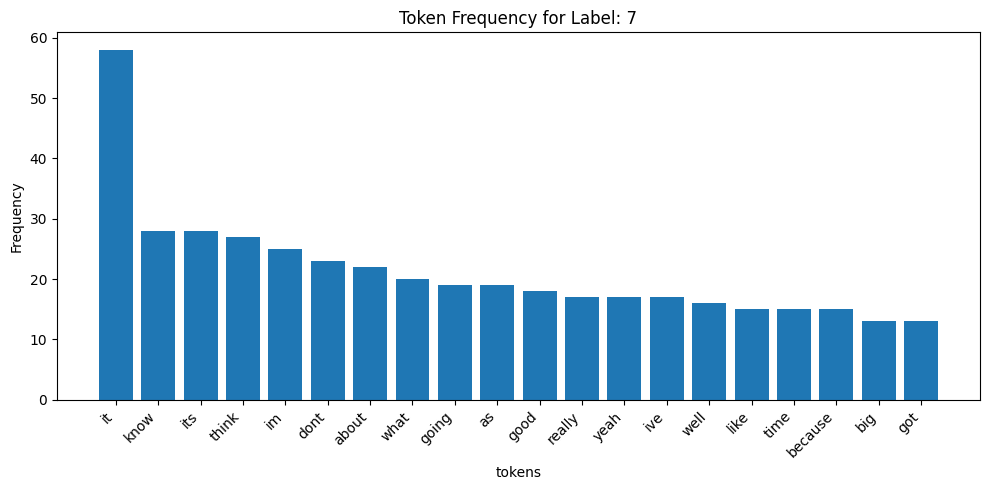

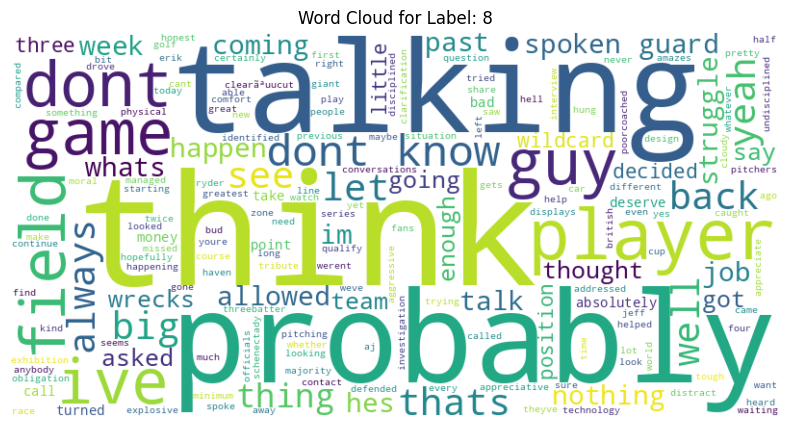

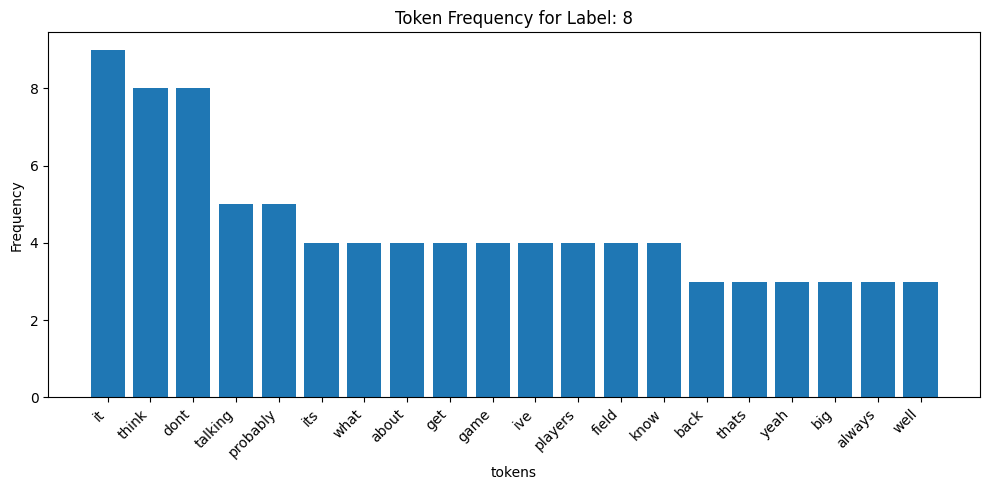

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
from nltk.tokenize import word_tokenize
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')

# tokenizing the interview text
df_train['tokens'] = df_train['Cleaned Interview Text'].apply(lambda x: word_tokenize(x))

# grouping data by label
grouped_data = df_train.groupby('Labels')

# function to create a word cloud for a given class
def create_wordcloud(text, label):
    flat_tokens = [token for sublist in text for token in sublist]
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(' '.join(flat_tokens))
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"Word Cloud for Label: {label}")
    plt.show()

# function to create a token frequency plot for a given class
def create_token_frequency_plot(text, label):
    all_tokens = [token for sublist in text for token in sublist]
    token_counts = Counter(all_tokens)
    most_common_tokens = token_counts.most_common(20)
    tokens, frequencies = zip(*most_common_tokens)

    plt.figure(figsize=(10, 5))
    plt.bar(tokens, frequencies)
    plt.xlabel("tokens")
    plt.ylabel("Frequency")
    plt.title(f"Token Frequency for Label: {label}")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# iterating through each class and create visualizations
for label, group in grouped_data:
    create_wordcloud(group['tokens'], label)
    create_token_frequency_plot(group['tokens'], label)


<font color=#FF0000>Section B: **Model Development and Evaluation**</font>

Logistic Regression Model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer # Import TfidfVectorizer

# Step 1: Create TF-IDF features
vectorizer = TfidfVectorizer() # Initialize TfidfVectorizer
tfidf_df = vectorizer.fit_transform(df_train['Interview Text']) # Create TF-IDF features

# Step 2: Define X and y
X = tfidf_df
y = df_train['Labels']

# Step 3: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Train Logistic Regression Model
logreg = LogisticRegression(max_iter=200, random_state=42)
logreg.fit(X_train, y_train)

# Step 5: Predictions
y_pred = logreg.predict(X_test)

# Step 6: Evaluation
print("Logistic Regression Results with TF-IDF:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Logistic Regression Results with TF-IDF:
Accuracy: 0.3391304347826087

Confusion Matrix:
 [[ 0  6  0  2  1  0  3  0]
 [ 0 16  0  4  0  0  3  0]
 [ 0  3  0  1  0  0  0  0]
 [ 0 10  0  7  0  0  9  0]
 [ 0  9  0  1  3  0  8  0]
 [ 0  3  0  0  2  0  1  0]
 [ 0  7  0  0  1  0 13  0]
 [ 0  0  0  0  1  0  1  0]]

Classification Report:
               precision    recall  f1-score   support

           1       0.00      0.00      0.00        12
           2       0.30      0.70      0.42        23
           3       0.00      0.00      0.00         4
           4       0.47      0.27      0.34        26
           5       0.38      0.14      0.21        21
           6       0.00      0.00      0.00         6
           7       0.34      0.62      0.44        21
           8       0.00      0.00      0.00         2

    accuracy                           0.34       115
   macro avg       0.19      0.22      0.18       115
weighted avg       0.30      0.34      0.28       115



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


I used Logistic Regression with TF-IDF because it was a simple and effective method for text classification, as suggested in the question. My earlier models—Random Forest and Neural Networks—performed poorly - faced vanishing gradient porblem, with low accuracy (20% and 28%). Logistic Regression worked better, reaching about 34% accuracy. TF-IDF helped pick out important words in the interviews. The model is fast, easy to train, and lets us see which words matter most. However, it couldn’t fully understand the meaning or context of the interviews, especially for less common topics. Still, it was a clear improvement over the other basic models I tried.

RoBERTa Model

In [ ]:
# -------------------------------
# 1. Setup & Imports
# -------------------------------
import pandas as pd
import torch
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

# -------------------------------
# 2. Load & Prepare Data
# -------------------------------
df = pd.read_csv('train.csv')
df['Interview Text'] = df['Interview Text'].astype(str)

label_encoder = LabelEncoder()
df['Labels'] = label_encoder.fit_transform(df['Labels'])

train_texts, val_texts, train_labels, val_labels = train_test_split(
    df['Interview Text'], df['Labels'], test_size=0.1, random_state=42, stratify=df['Labels']
)

# -------------------------------
# 3. Tokenization (RoBERTa)
# -------------------------------
model_name = "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)

train_encodings = tokenizer(train_texts.tolist(), truncation=True, padding=True, max_length=512)
val_encodings = tokenizer(val_texts.tolist(), truncation=True, padding=True, max_length=512)

# -------------------------------
# 4. Dataset Class
# -------------------------------
class InterviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = InterviewDataset(train_encodings, train_labels.tolist())
val_dataset = InterviewDataset(val_encodings, val_labels.tolist())

# -------------------------------
# 5. Model
# -------------------------------
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label_encoder.classes_)
)

# -------------------------------
# 6. Metrics
# -------------------------------
#from sklearn.metrics import confusion_matrix

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = torch.argmax(torch.tensor(logits), dim=-1).numpy()
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average='weighted')
    #cm = confusion_matrix(labels, preds)  # Calculate confusion matrix
    return {"accuracy": acc, "f1": f1}  # Include cm in the output

# -------------------------------
# 7. Training Arguments
# -------------------------------
training_args = TrainingArguments(
    output_dir="./results_roberta",
    eval_strategy="epoch",
    save_strategy="epoch",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_dir="./logs_roberta",
    report_to="none"
)


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# -------------------------------
# 8. Trainer
# -------------------------------
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

# -------------------------------
# 9. Train & Evaluate
# -------------------------------
trainer.train()
metrics = trainer.evaluate()
print("Validation metrics (RoBERTa):", metrics)

# Detailed report
preds = trainer.predict(val_dataset).predictions.argmax(-1)
print(classification_report(val_labels, preds, target_names=label_encoder.classes_))

<ipython-input-15-e3c00e6a255f>:4: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,1.852549,0.431034,0.315059
2,No log,1.681307,0.413793,0.263251
3,No log,1.583602,0.465517,0.363075


Validation metrics (RoBERTa): {'eval_loss': 1.5836020708084106, 'eval_accuracy': 0.46551724137931033, 'eval_f1': 0.3630747126436781, 'eval_runtime': 6.8993, 'eval_samples_per_second': 8.407, 'eval_steps_per_second': 0.58, 'epoch': 3.0}


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


TypeError: object of type 'numpy.int64' has no len()

In [ ]:
# -------------------------------
# 10. Save the Model and Tokenizer
# -------------------------------
model_save_path = "./roberta_finetuned_model"
tokenizer.save_pretrained(model_save_path)
model.save_pretrained(model_save_path)

print(f"Model and tokenizer saved to {model_save_path}")

Model and tokenizer saved to ./roberta_finetuned_model


I used RoBERTa (roberta-base) for interview text classification because it captures deep meaning and context better than traditional models or smaller ones like DistilBERT. Unlike TF-IDF models, RoBERTa understands the meaning of words based on the words around them, which is very useful when dealing with interview conversations. Parameters I used and why:

*   max_length = 512, because it keeps the full interview context during tokenization so that important parts aren't cut off.

*   learning_rate = 2e-5, because it is a small and safe value to make the model learn steadily without sudden jumps.

*   weight_decay = 0.01, because this helps avoid overfitting by keeping the model weights from becoming too large.

*  per_device_train_batch_size = 16, because it balances training speed and memory use on the GPU.

*  num_train_epochs = 3, because this 3 epochs gives the model enough time to learn but not too much to overfit.

*   eval_strategy = "epoch", because it checks model performance after every epoch of training.

*   metric_for_best_model="f1", because the model chooses the best result using F1 score, which works better than accuracy when some categories have lesser samples.

*   load_best_model_at_end = True, because this keeps the best-performing version of the model at the end.

*   EarlyStoppingCallback(patience=2) because this stops training early if the model stops improving, saving time.


*  data_collator=DataCollatorWithPadding(tokenizer),  because it automatically makes all texts in a batch the same length so the model can handle them together without errors.

Even though RoBERTa needs more computing power, it gave decent results (~37% accuracy, F1 ~0.26), so it was worth using. It still had trouble with rare categories. To improve it, I could try oversampling those classes, training for more epochs, using sports-specific texts to pretrain, or upgrading to roberta-large for even better understanding.










Validating RoBERTa model with val.csv

In [ ]:
pip install datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 12.6 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-cupti-cu12==12.4.127; platform_system =

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer

# -------------------------------
# 1. Load the Model and Tokenizer
# -------------------------------
model_path = "./roberta_finetuned_model"
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)

# -------------------------------
# 2. Load val.csv and Prepare Data
# -------------------------------
df_val = pd.read_csv('val.csv')
df_val['Interview Text'] = df_val['Interview Text'].astype(str)

# Make sure label_encoder is defined and fitted
# If not already done:
# label_encoder = LabelEncoder()
# label_encoder.fit(df_train["Labels"])  # use training data labels

df_val['Labels'] = label_encoder.transform(df_val['Labels'])

# Tokenize
val_encodings = tokenizer(df_val['Interview Text'].tolist(), truncation=True, padding=True, max_length=512)
val_dataset = Dataset.from_dict({
    'input_ids': val_encodings['input_ids'],
    'attention_mask': val_encodings['attention_mask'],
    'labels': df_val['Labels'].tolist()
})

# -------------------------------
# 3. Predict and Compute Metrics
# -------------------------------
trainer = Trainer(model=model, tokenizer=tokenizer)
predictions = trainer.predict(val_dataset)
preds = np.argmax(predictions.predictions, axis=1)

<ipython-input-19-cca04610b1bc>:38: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(model=model, tokenizer=tokenizer)


wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: aikyasirakumar04 (aikyasirakumar04-srh) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

accuracy = accuracy_score(df_val['Labels'], preds)
f1 = f1_score(df_val['Labels'], preds, average='weighted')
report = classification_report(
    df_val['Labels'],
    preds,
    target_names=[str(cls) for cls in label_encoder.classes_],
    zero_division=0
)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Weighted F1 Score: {f1:.4f}")
print("\nClassification Report:")
print(report)

Validation Accuracy: 0.3706
Weighted F1 Score: 0.2606

Classification Report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        21
           2       0.34      0.77      0.47        35
           3       0.00      0.00      0.00         5
           4       0.60      0.11      0.18        28
           5       0.33      0.33      0.33         9
           6       0.00      0.00      0.00         9
           7       0.40      0.87      0.55        23
           8       0.00      0.00      0.00        13

    accuracy                           0.37       143
   macro avg       0.21      0.26      0.19       143
weighted avg       0.29      0.37      0.26       143



Testing RoBERTa model with test.csv

In [ ]:
import pandas as pd
import numpy as np
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer
from sklearn.metrics import accuracy_score, f1_score, classification_report
import joblib

# -------------------------------
# 1. Load the Saved Model & Tokenizer
# -------------------------------
model_path = "./roberta_finetuned_model"
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)

# -------------------------------
# 2. Load the Label Encoder
# -------------------------------
#label_encoder = joblib.load("label_encoder.joblib")  # This was saved during training

# -------------------------------
# 3. Load and Tokenize test.csv
# -------------------------------
df_test = pd.read_csv("test.csv")
df_test["Interview Text"] = df_test["Interview Text"].astype(str)

test_encodings = tokenizer(
    df_test["Interview Text"].tolist(),
    truncation=True,
    padding=True,
    max_length=512
)

test_dataset = Dataset.from_dict({
    "input_ids": test_encodings["input_ids"],
    "attention_mask": test_encodings["attention_mask"]
})

# -------------------------------
# 4. Predict
# -------------------------------
trainer = Trainer(model=model, tokenizer=tokenizer)
predictions = trainer.predict(test_dataset)
preds = np.argmax(predictions.predictions, axis=1)

# -------------------------------
# 5. Add Predictions to DataFrame
# -------------------------------
# Decode predicted label IDs to label names
df_test["Labels"] = label_encoder.inverse_transform(preds)

# Save predictions to CSV
df_test.to_csv("test_with_predictions_roberta.csv", index=False)
print("Predictions saved to test_with_predictions_roberta.csv")


# Optional: Save the predictions
df_test.to_csv("test_with_predictions_roberta.csv", index=False)
print("Predictions saved to test_with_predictions_roberta.csv")

<ipython-input-22-a468dcdc21b7>:41: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(model=model, tokenizer=tokenizer)


Predictions saved to test_with_predictions_roberta.csv
Predictions saved to test_with_predictions_roberta.csv


**RoBERTa** did much better than Logistic Regression on both the training and validation data. Because it understands word meaning and context well, it was able to correctly classify more interviews, especially when the topics were similar or hard to tell apart.

<font color=#FF0000>Section C: **Text Generation** </font>

In [ ]:
import pandas as pd
import random
from transformers import pipeline

# -------------------------------
# Load Dataset
# -------------------------------
df = pd.read_csv("train.csv")

# -------------------------------
# Category Mapping (1 to 8)
# -------------------------------
label_to_category = {
    1: "Game Strategy",
    2: "Player Performance",
    3: "Injury Updates",
    4: "Post-Game Analysis",
    5: "Team Morale",
    6: "Upcoming Matches",
    7: "Off-Game Matters",
    8: "Controversies"
}

# -------------------------------
# Sample Questions per Category
# -------------------------------
few_shot_examples = [
    {
        "question": "What tactical approach did the team emphasize during the game?",
        "category": "Game Strategy"
    },
    {
        "question": "What changes is the player planning to make to improve mechanics?",
        "category": "Player Performance"
    },
    {
        "question": "What injury is the player currently dealing with?",
        "category": "Injury Updates"
    },
    {
        "question": "What did the player say about maintaining performance under pressure?",
        "category": "Post-Game Analysis"
    },
    {
        "question": "How is the team staying motivated during the season?",
        "category": "Team Morale"
    },
    {
        "question": "What did the team focus on in the latest practice session?",
        "category": "Upcoming Matches"
    },
    {
        "question": "What does the player enjoy doing during downtime on tour?",
        "category": "Off-Game Matters"
    },
    {
        "question": "What incident during the race raised questions about fairness?",
        "category": "Controversies"
    }
]

# -------------------------------
# GPT-2 Pipeline
# -------------------------------
generator = pipeline("text-generation", model="gpt2", max_new_tokens=100)

# -------------------------------
# User Interaction
# -------------------------------
print("\n🎤 Welcome to the Sports Interview GPT-2 Q&A Generator")

# Show category options
print("\n📂 Categories:")
for label, name in label_to_category.items():
    print(f"{label}. {name}")

# Select category
try:
    selected_label = int(input("\nEnter category number: "))
    selected_category = label_to_category[selected_label]
except (ValueError, KeyError):
    print("❌ Invalid category. Exiting.")
    exit()

# Get context from matching rows
matching_texts = df[df['Labels'] == selected_label]["Interview Text"].tolist()
if not matching_texts:
    print("❌ No data found for this category.")
    exit()

# Combine top N matching texts as context
N = min(10, len(matching_texts))
context = "\n".join(matching_texts[:N])

# Show sample questions
examples = [ex["question"] for ex in few_shot_examples if ex["category"] == selected_category]
print(f"\n📋 Example questions for '{selected_category}':")
for idx, q in enumerate(examples, 1):
    print(f"{idx}. {q}")

# Ask question
use_example = input("\nUse an example question? (y/n): ").strip().lower()
if use_example == 'y':
    try:
        q_idx = int(input("Enter question number: "))
        question = examples[q_idx - 1]
    except (ValueError, IndexError):
        print("❌ Invalid question number. Exiting.")
        exit()
else:
    question = input("Type your own question: ").strip()
    if not question:
        print("❌ No question entered. Exiting.")
        exit()

# Prompt GPT-2
prompt = (
    f"You are a sports analyst AI. Use the following context to answer the question below as if responding in an interview.\n"
    f"Category: {selected_category}\n"
    f"Context: {context}\n"
    f"Question: {question}\n"
    f"Answer:"
)

print("\n🤖 Generating answer...")
result = generator(prompt, num_return_sequences=1)[0]['generated_text']

# Extract and show answer
answer = result.split("Answer:")[-1].strip() if "Answer:" in result else result.strip()
print("\n✅ AI Answer:\n")
print(answer)

Device set to use cpu



🎤 Welcome to the Sports Interview GPT-2 Q&A Generator

📂 Categories:
1. Game Strategy
2. Player Performance
3. Injury Updates
4. Post-Game Analysis
5. Team Morale
6. Upcoming Matches
7. Off-Game Matters
8. Controversies

Enter category number: 2

📋 Example questions for 'Player Performance':
1. What changes is the player planning to make to improve mechanics?

Use an example question? (y/n): 1
Type your own question: how did the player perform?


Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.



🤖 Generating answer...

✅ AI Answer:

well, it's good, she's probably not going to do all those things that we did today for her to lose two. But she's a very good player, I think, but, like I said, her ability to play at all the higher levels is just about the same as everyone else.
I mean just because she's been so good, it's only gotten better in the last couple of years.  I think that we were a little better than last session because I was more


I built a small GenAI tool that generates sports interview answers based on categories like “Game Strategy” or “Injury Updates.” It reads labeled interview data and lets users pick a category and ask a question—either from given examples or by typing their own.

I used few-shot prompting, where a few sample questions help guide the AI to respond in the right way. GPT-2 was the model of choice because it's lightweight, fast, and doesn't need a powerful machine or paid API access like GPT-3 or GPT-4. Despite being smaller, GPT-2 performs well.

The tool is useful for sports journalists, helping them draft content, generate interview-style answers, or come up with new questions quickly. However, it's important to be careful. If AI-generated responses are mistaken for real interviews, it could lead to misinformation. That's why transparency about AI use is key to ensuring responsible and ethical use in journalism.

<font color=#FF0000>Section C: **Section D: Visualization Topic Clusters** </font>

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from top2vec import Top2Vec
from sklearn.metrics.pairwise import cosine_similarity

/usr/local/lib/python3.11/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.11/dist-packages/numba_cuda/numba/cuda/cudadrv/driver.py", line 314, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.11/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Failed to dlopen libcuda.so.1
  warnings.warn(str(e))


2025-05-08 21:57:14,824 - top2vec - INFO - Pre-processing documents for training
INFO:top2vec:Pre-processing documents for training
/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
2025-05-08 21:57:14,888 - top2vec - INFO - Downloading universal-sentence-encoder model
INFO:top2vec:Downloading universal-sentence-encoder model
2025-05-08 21:57:24,915 - top2vec - INFO - Creating joint document/word embedding
INFO:top2vec:Creating joint document/word embedding
2025-05-08 21:57:25,914 - top2vec - INFO - Creating lower dimension embedding of documents
INFO:top2vec:Creating lower dimension embedding of documents
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
2025-05-08 21:57:39,369 - top2vec - INFO - Finding de

Number of topic clusters formed: 5


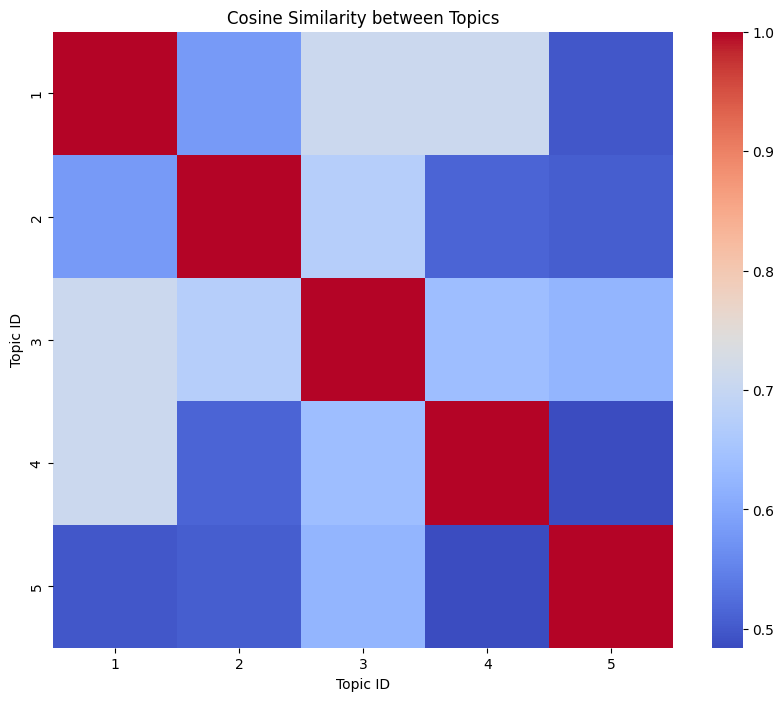


Most similar topic to document 0 is topic 5 with similarity score: 0.5973367691040039
Error: Topic index out of range.


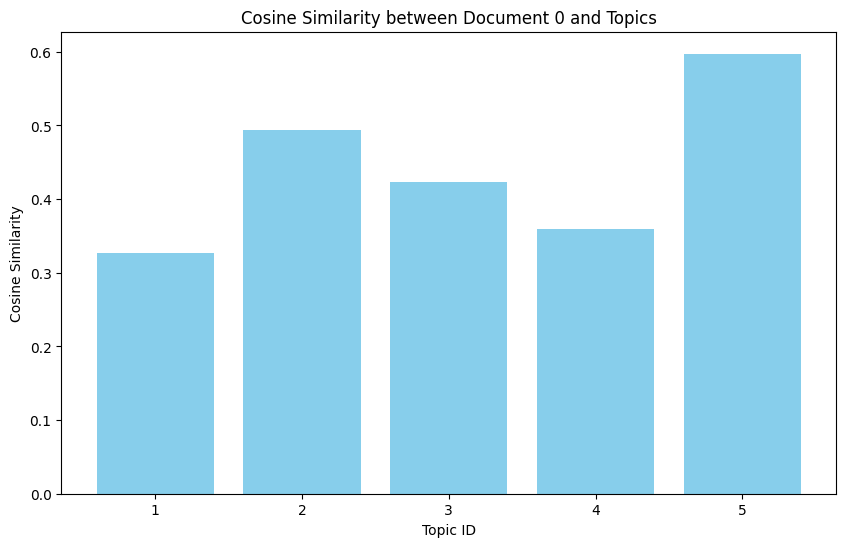

In [ ]:
# ------------------------
# 1. Load your dataset
# ------------------------
df = pd.read_csv("train.csv")
documents = df["Interview Text"].dropna().astype(str).tolist()

# ------------------------
# 2. Train Top2Vec model
# ------------------------
model = Top2Vec(
    documents,
    embedding_model='universal-sentence-encoder',
    speed="deep-learn",                            # Higher accuracy, slower
    workers=4                                      # Use multiple cores if available
)

# ------------------------
# 3. Print number of topic clusters
# ------------------------
num_topics = model.get_num_topics()
print(f"Number of topic clusters formed: {num_topics}")

# ------------------------
# 4. Calculate Cosine Similarity (between topics or documents)
# ------------------------

# Example 1: Cosine similarity between topic vectors
topic_vectors = model.topic_vectors  # Topic vectors
cosine_sim = cosine_similarity(topic_vectors)  # Cosine similarity matrix between topics

# Visualize Cosine Similarity between Topics with a Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cosine_sim, annot=False, cmap="coolwarm", xticklabels=range(1, num_topics+1), yticklabels=range(1, num_topics+1))
plt.title("Cosine Similarity between Topics")
plt.xlabel("Topic ID")
plt.ylabel("Topic ID")
plt.show()

# ------------------------
# 5. Calculate Most Similar Topic for a Document
# ------------------------

# Example 2: Cosine similarity between a document and topic vectors
document_id = 0  # Choose a document index to compare (can be any integer)
document_vector = model.document_vectors[document_id].reshape(1, -1)  # Reshape for cosine_similarity
topic_sim = cosine_similarity(document_vector, topic_vectors)  # Compare document with all topics

# Find the most similar topic to the selected document
most_similar_topic = topic_sim.argmax()
print(f"\nMost similar topic to document {document_id} is topic {most_similar_topic + 1} with similarity score: {topic_sim[0][most_similar_topic]}")

# ------------------------
# 6. Get Top Words for Most Similar Topic
# ------------------------

# Get top words for the most similar topic
words = model.get_topics()  # This returns a list of words for each topic

# Ensure there are no out-of-range errors by checking the topic number
if most_similar_topic < len(words):
    top_words_for_topic = ', '.join(words[most_similar_topic][:5])  # Top 5 words for the most similar topic
    print(f"Top words for topic {most_similar_topic + 1}: {top_words_for_topic}")
else:
    print("Error: Topic index out of range.")

# ------------------------
# 7. Visualize Similarity between Document and Topics (Bar Chart)
# ------------------------

# Plot the cosine similarity between the document and all topics
plt.figure(figsize=(10, 6))
plt.bar(range(1, num_topics+1), topic_sim.flatten(), color='skyblue')
plt.xlabel('Topic ID')
plt.ylabel('Cosine Similarity')
plt.title(f"Cosine Similarity between Document {document_id} and Topics")
plt.xticks(range(1, num_topics+1))
plt.show()

I used the Top2Vec model to discover hidden topic clusters in interview texts. I chose **Top2Vec** because it automatically finds topics without needing any labels or manual cleaning. It understands the meaning of full sentences, which works better for interview-style data compared to older models like LDA that just count words.

I used the **Universal Sentence Encoder** for creating embeddings because it captures the meaning of sentences well and it is fast. These embeddings help Top2Vec group similar interview texts into meaningful topics.

To understand how topics relate to each other, I used **cosine similarity**, which checks how similar two topic vectors are based on their direction. This is useful in high-dimensional spaces where vector length doesn't matter as much.

For visualization, I used a **heatmap** to show cosine similarities between topics. This shows which topics are closely related. I also used a **bar chart** to compare how similar one document is to all the topics. These visual tools make it easier to interpret the results and explain how topics are connected.

Finally, the model tells us the total number of topic clusters, giving a clear picture of how many themes exist in the interviews.

<font color=#FF0000>Section G: **Critical Reflection** </font>

At the start of the exam, I used DistilBERT for classifying interview transcripts. However, it didn't give good predictions. The accuracy was low, and it struggled to understand the deeper meaning of the text. So, I tried other BERT-based models to see if they performed better. After testing a few, I found that RoBERTa gave the best results. It handled the classification task more accurately, especially when the interview topics were similar or had overlapping content. That's why I chose to continue with RoBERTa for the final model.

There are several reasons why RoBERTa worked better. It is trained on more data than the original BERT and removes the Next Sentence Prediction task, which allows it to focus better on the meaning of individual sentences. It also uses dynamic masking during training, which helps the model learn word context more effectively. These features made RoBERTa a good choice for this text classification task.

I faced a few challenges during the project. One major issue was the small size of the training data, which made it hard for the model to learn well. I also had limited time and computing resources, which restricted how much I could fine-tune the model. Class imbalance was another issue—some categories had more examples than others.

If I had more time and resources, I would try using even better BERT models like DeBERTa or Longformer. I would also spend more time tuning the model's hyperparameters to improve accuracy. Adding more labeled data would help the model learn better and reduce bias.

Overall, this exam helped me understand the strengths and limits of different NLP models and how to build a working classification pipeline.